# PRACTICAL — 10 (Mini Project)
## Time Series Analysis and Forecasting of Onion Prices at Pune APMC

---

## 1. Aim
To perform time series analysis on daily onion market prices of Pune APMC and to build, evaluate and compare
forecasting models that predict the weekly modal price of onion for October–December 2026.

## 2. Objectives
1. To load, inspect and clean a real-world agricultural market price dataset.
2. To convert irregular daily market data into a regular **weekly** time series and handle gaps.
3. To study the components of a time series — **trend, seasonality and noise** — using plots and seasonal decomposition.
4. To study the relation between **price and arrivals** (supply) of onion.
5. To check **stationarity** using the Augmented Dickey–Fuller (ADF) test and to read **ACF/PACF** plots.
6. To split time series data correctly (by time, without shuffling) and avoid **data leakage**.
7. To build forecasting models: Naive, Seasonal-Naive, **SARIMA**, **SARIMAX** and a lag-feature **Random Forest**.
8. To evaluate the models using **MAE, RMSE and MAPE** and compare them against the naive baseline.
9. To forecast Oct–Dec 2026 prices with **prediction intervals**.

## 3. Theory

**Time series:** A time series is a sequence of observations recorded at regular time intervals (daily, weekly, monthly).
Unlike ordinary data, the **order** of observations matters, because today's value depends on past values.

**Components of a time series:**
* **Trend** – the long-term upward or downward movement (e.g. general price inflation).
* **Seasonality** – a pattern that repeats every fixed period (e.g. onion prices rise every year in Sep–Dec before the new *kharif* crop arrives).
* **Cyclic / irregular (noise)** – the remaining random variation (e.g. sudden spikes after crop damage due to unseasonal rain).

**Stationarity:** A series is *stationary* if its mean and variance do not change over time. Models like ARIMA assume
stationarity. The **Augmented Dickey–Fuller (ADF) test** checks this:
*H₀: the series has a unit root (non-stationary)*. If **p-value < 0.05** we reject H₀ and treat the series as stationary.
If it is not stationary, we use **differencing** (yₜ − yₜ₋₁).

**ACF and PACF:**
* **ACF (Autocorrelation Function)** – correlation of the series with its own past values (lags).
* **PACF (Partial ACF)** – correlation with a lag after removing the effect of shorter lags.
They help to choose the AR (p) and MA (q) orders of an ARIMA model.

**Forecasting models used:**
* **Naive** – forecast = last observed value. Very simple, but often hard to beat for prices.
* **Seasonal Naive** – forecast = value from the same week last year.
* **ARIMA(p,d,q)** – AutoRegressive (past values) + Integrated (differencing) + Moving Average (past errors).
* **SARIMA(p,d,q)(P,D,Q,s)** – ARIMA with an extra seasonal part repeating every *s* periods (s = 52 weeks).
* **SARIMAX** – SARIMA plus an **eXogenous** (external) variable; here, onion **arrivals** (supply).
* **Lag-feature Random Forest** – a machine-learning regressor that uses past prices (lags), rolling means and the month as input features.

**Time-based train/test split:** For time series we must **not shuffle** the data. The model is trained on the past and
tested on the future, exactly like it will be used in reality. Using any future value while training is called
**data leakage** and gives falsely good results.

**Evaluation metrics** (A = actual, F = forecast, n = number of points):
* **MAE** = (1/n) Σ |A − F| → average error in Rs/quintal.
* **RMSE** = √[(1/n) Σ (A − F)²] → like MAE but punishes big errors more.
* **MAPE** = (100/n) Σ |A − F| / A → average error in percent.

## 4. Dataset Description

**File:** `onion_pune_mumbai_2012_2026.csv`
**Source:** CEDA (Centre for Economic Data and Analysis), Ashoka University — compiled from **Agmarknet** (Govt. of India).
**Coverage:** 16 mandis (markets) in Pune, Thane and Mumbai districts, 01-Jan-2012 to 28-Sep-2026.
**Scope of this project:** only `market == "Pune"` (the main Pune APMC, ~275 trading days per year).

| Column | Description | Issue present |
|---|---|---|
| date | Trading date | Stored as text; Sundays / holidays missing |
| district | District name | – |
| market | Mandi (market) name | 16 markets mixed together |
| commodity | Commodity (Onion) | – |
| min_price | Minimum price of the day (Rs/quintal) | Missing on some days |
| max_price | Maximum price of the day (Rs/quintal) | Missing on some days |
| **modal_price** | Most common price of the day (Rs/quintal) — **target** | Missing on some days, extreme spikes |
| arrivals_tonnes | Quantity of onion arriving in the market (tonnes) | Missing on some days, very low values |

*1 quintal = 100 kg. So Rs 2,000/quintal = Rs 20/kg at the wholesale level.*

## 5. Algorithm
1. Start.
2. Import the libraries — Pandas, NumPy, Matplotlib, Statsmodels and Scikit-learn.
3. Load the dataset, keep only the Pune market and explore it using `shape`, `info()`, `describe()` and `isnull().sum()`.
4. Clean the data: convert `date` to datetime, sort, remove duplicates, drop days without a price, and check outliers using the IQR method.
5. Resample the daily data to a **weekly** series (mean modal price, sum of arrivals) and fill the empty weeks by interpolation.
6. Perform EDA: trend plot, seasonal decomposition, monthly seasonality, price vs arrivals, ACF/PACF and the ADF test.
7. Split the data by time: train up to Sep-2025, test Oct-2025 to Sep-2026.
8. Build models: Naive, Seasonal-Naive, SARIMA, SARIMAX (with arrivals) and lag-feature Random Forest.
9. Evaluate every model on the test set using MAE, RMSE and MAPE, compare them in a table and plot forecast vs actual.
10. Retrain the best model on all the data and forecast Oct–Dec 2026 with prediction intervals.
11. Stop.

## 6. Python Program

### Step 1: Import libraries and load the dataset

**Why:** Before modelling we must know what we are working with — columns, data types, missing values and the date range.
We keep only the **Pune** market so that we model **one** consistent price series, not a mix of 16 different mandis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')        # hide statsmodels convergence messages
plt.rcParams['figure.figsize'] = (12, 4)
os.makedirs('figures', exist_ok=True)   # plots are also saved here for the README

SOURCE = 'Source: CEDA (Ashoka University), based on Agmarknet'

def add_source():
    # Credit the data source at the bottom of every chart
    plt.figtext(0.01, -0.03, SOURCE, fontsize=8, color='gray')

In [2]:
# Read the file
df_all = pd.read_csv('onion_pune_mumbai_2012_2026.csv')
print('Full dataset shape:', df_all.shape)
print('\nRows per market:')
print(df_all['market'].value_counts())

Full dataset shape: (29619, 8)

Rows per market:
market
Pune            4021
Vashi           3961
Pimpri          3447
Khadki          3092
Kalyan          2608
Manjri          1866
Moshi           1820
Khed(Chakan)    1779
Manchar         1473
Alephata        1441
Junnar          1136
Narayangaon      955
Otur             799
Indapur          682
Baramati         481
Shirur            58
Name: count, dtype: int64


In [3]:
# Keep only the main Pune APMC
df = df_all[df_all['market'] == 'Pune'].copy()
print('Pune shape:', df.shape)
df.head()

Pune shape: (4021, 8)


,date,district,market,commodity,min_price,max_price,modal_price,arrivals_tonnes
21579,2012-01-01,Pune,Pune,Onion,350.0,700.0,520.0,1662.4
21580,2012-01-02,Pune,Pune,Onion,300.0,600.0,450.0,1583.6
21581,2012-01-03,Pune,Pune,Onion,NaN,NaN,NaN,1288.8
21582,2012-01-04,Pune,Pune,Onion,300.0,650.0,475.0,963.0
21583,2012-01-05,Pune,Pune,Onion,300.0,650.0,475.0,1243.3


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4021 entries, 21579 to 25599
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             4021 non-null   object 
 1   district         4021 non-null   object 
 2   market           4021 non-null   object 
 3   commodity        4021 non-null   object 
 4   min_price        3963 non-null   float64
 5   max_price        3963 non-null   float64
 6   modal_price      3963 non-null   float64
 7   arrivals_tonnes  3966 non-null   float64
dtypes: float64(4), object(4)
memory usage: 282.7+ KB


In [5]:
# Check missing values
df.isnull().sum()

date                0
district            0
market              0
commodity           0
min_price          58
max_price          58
modal_price        58
arrivals_tonnes    55
dtype: int64

In [6]:
print('First date:', df['date'].min())
print('Last date :', df['date'].max())
print('Commodities:', df['commodity'].unique())
df[['min_price', 'max_price', 'modal_price', 'arrivals_tonnes']].describe()

First date: 2012-01-01
Last date : 2026-09-24
Commodities: ['Onion']


,min_price,max_price,modal_price,arrivals_tonnes
count,3963.000000,3963.000000,3963.000000,3966.000000
mean,768.748675,2014.193793,1428.686601,1209.805371
std,594.082050,1415.060240,969.721170,574.554537
min,200.000000,400.000000,300.000000,1.000000
25%,400.000000,1100.000000,800.000000,841.250000
50%,600.000000,1600.000000,1100.000000,1116.750000
75%,800.000000,2500.000000,1750.000000,1474.000000
max,5500.000000,14000.000000,7500.000000,4427.600000


**Observation:** Pune is the largest market (4,021 days, 2012-01-01 to 2026-09-24), and the only commodity is Onion. That is about 273 rows a year instead of 365, because the APMC is closed on Sundays and holidays. `date` is stored as text (object). 58 days have no price (min, max and modal are all missing together) and 55 days have no arrivals, which is under 1.5% of rows. The modal price is right-skewed: median Rs 1,100 but mean Rs 1,429, with a maximum of Rs 7,500. This means prices are usually moderate but occasionally spike very high.

### Step 2: Clean the data

**Why:** A time series model needs real dates in the correct order, one row per day, and no impossible values.
* `date` is stored as text → convert it with `pd.to_datetime()`.
* Check for duplicate dates (two prices for the same day would confuse the model).
* Days with no price cannot be used → drop them (they will be filled later at the weekly level).
* Check outliers with the **IQR method** (as in Practical 1) — but **verify before removing**, because a price spike may be a real event.

In [7]:
# Convert date from text to datetime and sort
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Duplicates
print('Duplicate rows :', df.duplicated().sum())
print('Duplicate dates:', df['date'].duplicated().sum())
print('\nUpdated data types:')
print(df.dtypes)

Duplicate rows : 0
Duplicate dates: 0

Updated data types:
date               datetime64[ns]
district                   object
market                     object
commodity                  object
min_price                 float64
max_price                 float64
modal_price               float64
arrivals_tonnes           float64
dtype: object


In [8]:
# Where are the missing prices? (count by month)
missing = df[df['modal_price'].isnull()]
print('Days with no price:', len(missing))
print(missing['date'].dt.to_period('M').value_counts().head(8))

Days with no price: 58
date
2023-12    13
2014-08     9
2014-09     9
2024-12     8
2013-12     5
2013-08     2
2012-03     1
2012-01     1
Freq: M, Name: count, dtype: int64


In [9]:
# Sanity check: modal price must lie between min and max price
bad = df[(df['modal_price'] < df['min_price']) | (df['modal_price'] > df['max_price'])]
print('Rows where modal price is outside [min, max]:', len(bad))

# Drop the days that have no price at all
df = df.dropna(subset=['modal_price'])
print('Shape after dropping missing prices:', df.shape)

Rows where modal price is outside [min, max]: 0


Shape after dropping missing prices: (3963, 8)


In [10]:
# Outlier detection using the IQR method
Q1 = df['modal_price'].quantile(0.25)
Q3 = df['modal_price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print('Lower bound:', lower_bound, ' Upper bound:', upper_bound)

outliers = df[(df['modal_price'] > upper_bound) | (df['modal_price'] < lower_bound)]
print('Number of IQR outliers:', len(outliers))
print('\nOutliers by year:')
print(outliers['date'].dt.year.value_counts().sort_index())

Lower bound: -625.0  Upper bound: 3175.0
Number of IQR outliers: 293

Outliers by year:
date
2013    43
2015    81
2017     8
2019    36
2020    16
2023    22
2024    86
2026     1
Name: count, dtype: int64


In [11]:
# The highest prices and the lowest arrivals - are they errors or real events?
print('Top 5 prices:')
print(df.nlargest(5, 'modal_price')[['date', 'modal_price', 'arrivals_tonnes']])
print('\nLowest 5 arrivals:')
print(df.nsmallest(5, 'arrivals_tonnes')[['date', 'modal_price', 'arrivals_tonnes']])

Top 5 prices:
           date  modal_price  arrivals_tonnes
2159 2019-12-16       7500.0            828.0
2150 2019-12-05       7000.0            822.0
2151 2019-12-06       7000.0            972.0
2152 2019-12-08       6500.0           1119.0
2153 2019-12-09       6500.0            907.0

Lowest 5 arrivals:
           date  modal_price  arrivals_tonnes
1150 2016-07-11       1200.0              1.0
2248 2020-04-07       1450.0              5.0
2243 2020-03-31       2150.0              7.0
2241 2020-03-29       1900.0             10.0
2246 2020-04-05       1700.0             11.0


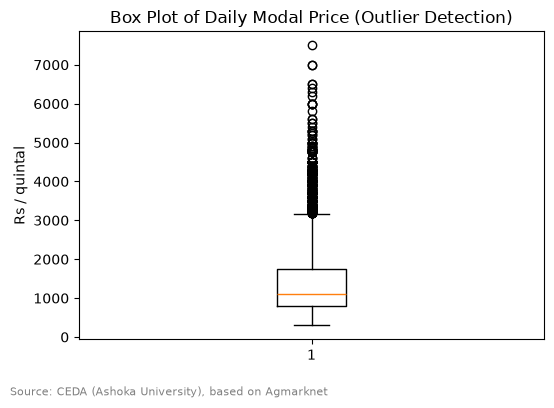

In [12]:
plt.figure(figsize=(6, 4))
plt.boxplot(df['modal_price'])
plt.title('Box Plot of Daily Modal Price (Outlier Detection)')
plt.ylabel('Rs / quintal')
add_source()
plt.show()

**Observation:** There are no duplicates, and the modal price is always between min and max. The missing prices are clustered: December 2023 (13 days) and Aug–Sep 2014. The IQR method flags 293 days above Rs 3,175, but they fall in specific years (2013, 2015, 2019, 2023, 2024). These are the well-known onion price crises: crop damage from unseasonal rain, and the export ban in Dec 2023. The top prices (Rs 6,500–7,500) are all from December 2019, when unseasonal rain destroyed the kharif crop. The lowest arrivals (1–11 tonnes) are mostly from the COVID lockdown (Mar–Apr 2020). **These are real events, not errors, so we do NOT cap or remove them.** Capping them would teach the model that price crises never happen. Unlike Practical 1 (Age = 150 was clearly impossible), here an extreme value is genuine information.

### Step 3: Resample to a weekly series and handle gaps

**Why:** The daily data is irregular — the market is closed on Sundays and holidays, so the gap between rows changes.
Time series models expect **equally spaced** points. Taking the **weekly** average:
* gives exactly one value per week (regular spacing),
* automatically covers the missing days inside a week,
* removes day-to-day noise, so the real pattern is easier to see.

For **price** we take the weekly **mean**; for **arrivals** we take the weekly **sum** (total supply that week).
A few weeks have no data at all (e.g. the COVID lockdown in 2020 and December 2023) — we fill them by
**linear interpolation** (a straight line between the neighbouring weeks).

In [13]:
daily = df.set_index('date')

weekly = pd.DataFrame()
weekly['price'] = daily['modal_price'].resample('W').mean()
weekly['arrivals'] = daily['arrivals_tonnes'].resample('W').sum(min_count=1)   # min_count=1 -> empty week stays NaN

print('Number of weeks:', len(weekly))
print('\nEmpty weeks before filling:')
print(weekly.isnull().sum())
print('\nWeeks with no price:')
print(weekly[weekly['price'].isnull()].index.date)

Number of weeks: 770

Empty weeks before filling:
price       18
arrivals    27
dtype: int64

Weeks with no price:
[datetime.date(2013, 6, 9) datetime.date(2013, 6, 16)
 datetime.date(2013, 12, 15) datetime.date(2013, 12, 22)
 datetime.date(2014, 5, 25) datetime.date(2014, 6, 8)
 datetime.date(2020, 4, 19) datetime.date(2020, 4, 26)
 datetime.date(2020, 5, 3) datetime.date(2020, 5, 10)
 datetime.date(2020, 5, 17) datetime.date(2020, 5, 24)
 datetime.date(2020, 10, 25) datetime.date(2023, 12, 10)
 datetime.date(2023, 12, 17) datetime.date(2023, 12, 24)
 datetime.date(2023, 12, 31) datetime.date(2024, 12, 22)]


In [14]:
# Fill empty weeks by linear interpolation
weekly = weekly.interpolate(method='linear')
print('Missing values after interpolation:')
print(weekly.isnull().sum())
print('\nWeekly data from', weekly.index.min().date(), 'to', weekly.index.max().date())
weekly.tail()

Missing values after interpolation:
price       0
arrivals    0
dtype: int64

Weekly data from 2012-01-01 to 2026-09-27


,price,arrivals
date,,
2026-08-30,2783.333333,5683.9
2026-09-06,2870.000000,5135.6
2026-09-13,2983.333333,5171.6
2026-09-20,2975.000000,3599.0
2026-09-27,2866.666667,2418.6


**Observation:** The weekly series has 770 weeks. 18 weeks had no price at all: the COVID lockdown (Apr–May 2020), December 2023 and a few isolated weeks. They were filled by linear interpolation. After this the series is complete and regular (one value every Sunday-ending week). The last week (ending 27-Sep-2026) only has data up to 24-Sep, so its arrivals total is lower than a full week's.

### Step 4: Exploratory Data Analysis (EDA)

#### 4.1 Trend
**Why:** First look at the whole series. A 52-week rolling mean (average of the last one year) shows the long-term **trend**
by smoothing out the seasonal ups and downs.

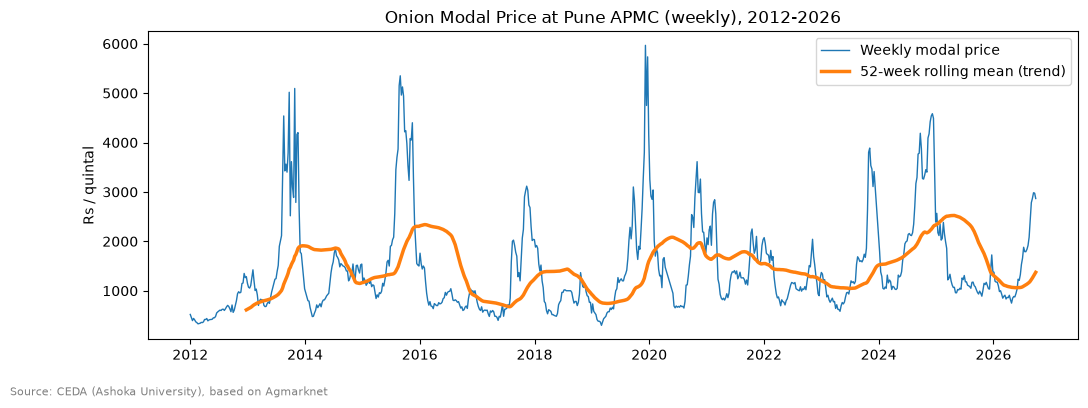

In [15]:
plt.plot(weekly.index, weekly['price'], label='Weekly modal price', linewidth=1)
plt.plot(weekly.index, weekly['price'].rolling(52).mean(), label='52-week rolling mean (trend)', linewidth=2.5)
plt.title('Onion Modal Price at Pune APMC (weekly), 2012-2026')
plt.ylabel('Rs / quintal')
plt.legend()
add_source()
plt.savefig('figures/01_trend.png', bbox_inches='tight')
plt.show()

**Observation:** There is no steady upward trend. Instead prices move in **boom–bust cycles**: big spikes in 2013, 2015, 2019–20, 2023 and 2024, each followed by a crash back to around Rs 1,000. Between spikes the price stays fairly low. In 2026 prices started rising again from June, reaching about Rs 3,000 by September.

#### 4.2 Seasonal decomposition
**Why:** `seasonal_decompose` splits the series into **Trend + Seasonal + Residual** (additive model, period = 52 weeks),
so we can see each component separately.

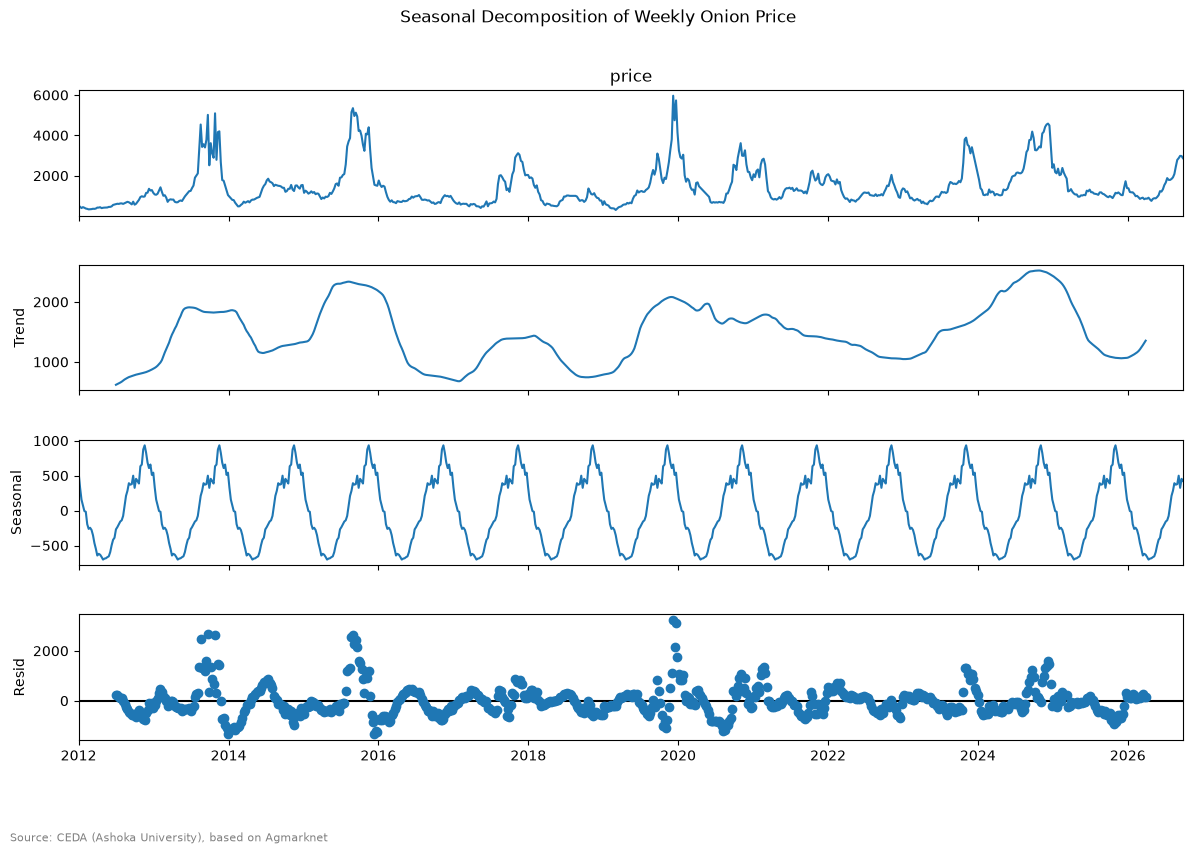

In [16]:
decomp = seasonal_decompose(weekly['price'], model='additive', period=52)
fig = decomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Seasonal Decomposition of Weekly Onion Price', y=1.01)
add_source()
plt.savefig('figures/02_decomposition.png', bbox_inches='tight')
plt.show()

**Observation:** The **seasonal** component is clear and repeats every year: lowest around April–May (the rabi harvest floods the market) and highest around October–November (stored rabi onion runs out before the new kharif crop arrives), a swing of about ±Rs 700. The **trend** component wanders up and down with the crisis years. The **residual** has large spikes in 2013, 2015 and 2019, which are crises that neither trend nor seasonality can explain. This is why onion prices are so hard to forecast.

#### 4.3 Monthly seasonality
**Why:** Group the prices by calendar month to see which months are usually expensive or cheap.

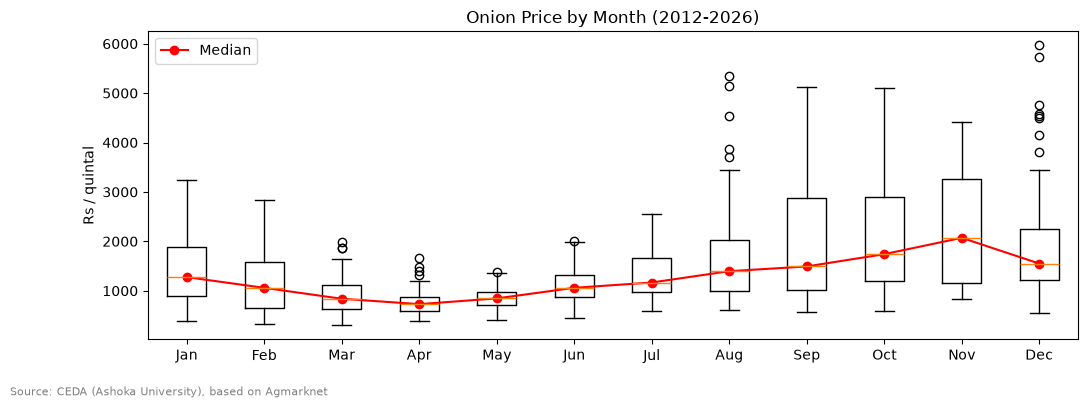

month
Jan    1276.0
Feb    1058.0
Mar     838.0
Apr     729.0
May     845.0
Jun    1059.0
Jul    1167.0
Aug    1396.0
Sep    1492.0
Oct    1740.0
Nov    2071.0
Dec    1550.0
Name: price, dtype: float64


In [17]:
weekly['month'] = weekly.index.month
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

monthly_data = [weekly.loc[weekly['month'] == m, 'price'] for m in range(1, 13)]
plt.figure(figsize=(12, 4))
plt.boxplot(monthly_data, tick_labels=month_names)
plt.plot(range(1, 13), weekly.groupby('month')['price'].median(), color='red', marker='o', label='Median')
plt.title('Onion Price by Month (2012-2026)')
plt.ylabel('Rs / quintal')
plt.legend()
add_source()
plt.savefig('figures/03_monthly_seasonality.png', bbox_inches='tight')
plt.show()

print(weekly.groupby('month')['price'].median().rename(index=dict(enumerate(month_names, 1))).round(0))

**Observation:** The median price is lowest in April (Rs 729) and highest in November (Rs 2,071), almost 3 times higher. Prices climb steadily from May to November and then fall in December–January when the kharif crop arrives. The boxes for Aug–Dec are also much taller, so these months are the most volatile. That matters because our forecast period (Oct–Dec) is the most uncertain time of the year.

#### 4.4 Price vs arrivals
**Why:** Economics says: when supply (arrivals) is high, price should fall. If this is true in the data,
arrivals can be a useful **external variable** for SARIMAX.

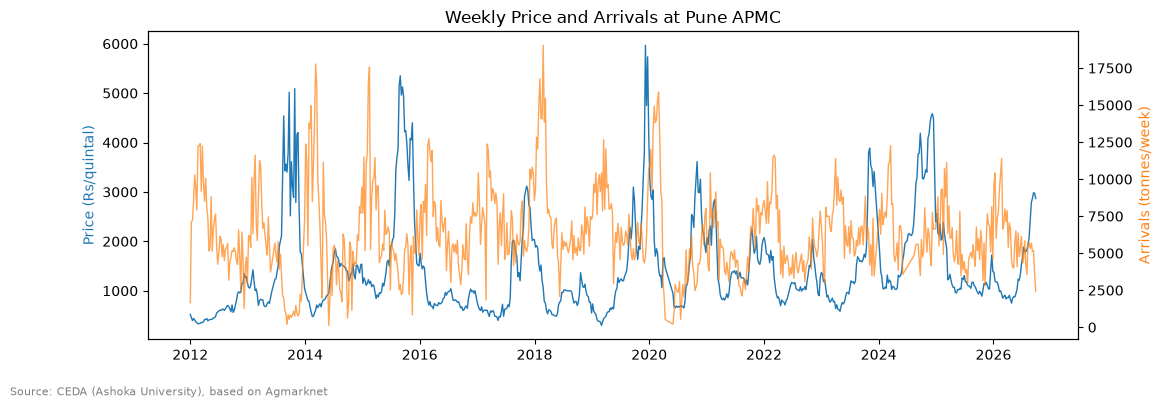

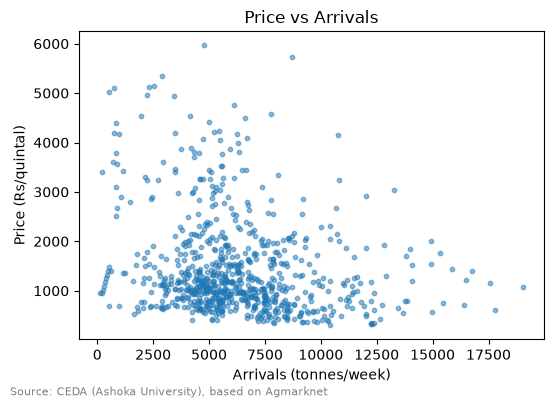

Correlation (price, arrivals): -0.223
Correlation (price, arrivals 4 weeks earlier): -0.276


In [18]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(weekly.index, weekly['price'], color='tab:blue', linewidth=1)
ax1.set_ylabel('Price (Rs/quintal)', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly['arrivals'], color='tab:orange', linewidth=1, alpha=0.7)
ax2.set_ylabel('Arrivals (tonnes/week)', color='tab:orange')
plt.title('Weekly Price and Arrivals at Pune APMC')
add_source()
plt.savefig('figures/04_price_arrivals_time.png', bbox_inches='tight')
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(weekly['arrivals'], weekly['price'], s=10, alpha=0.5)
plt.xlabel('Arrivals (tonnes/week)')
plt.ylabel('Price (Rs/quintal)')
plt.title('Price vs Arrivals')
add_source()
plt.savefig('figures/05_price_vs_arrivals.png', bbox_inches='tight')
plt.show()

print('Correlation (price, arrivals):', round(weekly['price'].corr(weekly['arrivals']), 3))
print('Correlation (price, arrivals 4 weeks earlier):', round(weekly['price'].corr(weekly['arrivals'].shift(4)), 3))

**Observation:** The correlation between price and arrivals is negative, as economics predicts (more supply leads to a lower price), but it is weak: −0.22, and −0.28 with arrivals from 4 weeks earlier. The scatter plot shows that high prices happen only when arrivals are low, but low arrivals do not always mean a high price. So arrivals may help a little, but not much.

#### 4.5 Stationarity test (ADF)
**Why:** ARIMA-type models need a stationary series. We test the price, the **log** of the price (log reduces the effect of
huge spikes) and the differenced price.

In [19]:
def adf_test(series, name):
    result = adfuller(series.dropna())
    print(f'{name:25s}  ADF statistic = {result[0]:7.3f}   p-value = {result[1]:.6f}   ->',
          'Stationary' if result[1] < 0.05 else 'NOT stationary')

adf_test(weekly['price'], 'Price')
adf_test(np.log(weekly['price']), 'Log price')
adf_test(weekly['price'].diff(), 'Differenced price')

Price                      ADF statistic =  -6.167   p-value = 0.000000   -> Stationary
Log price                  ADF statistic =  -6.141   p-value = 0.000000   -> Stationary


Differenced price          ADF statistic =  -7.439   p-value = 0.000000   -> Stationary


**Observation:** All three series have p-value < 0.05, so the weekly price is **stationary** even without differencing. That sounds surprising for prices, but it matches the trend plot: onion prices always come back down to a normal level after a spike (they are *mean-reverting*). So we use **d = 0** in SARIMA.

#### 4.6 ACF and PACF
**Why:** ACF/PACF show how strongly this week's price is related to past weeks. This guides the choice of p and q.

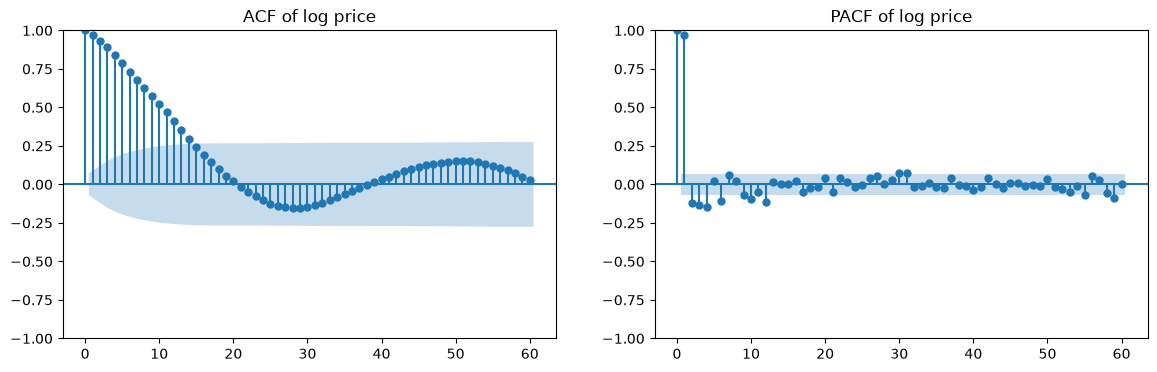

In [20]:
log_price = np.log(weekly['price'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(log_price, lags=60, ax=axes[0])
plot_pacf(log_price, lags=60, ax=axes[1], method='ywm')
axes[0].set_title('ACF of log price')
axes[1].set_title('PACF of log price')
plt.savefig('figures/06_acf_pacf.png', bbox_inches='tight')
plt.show()

**Observation:** The ACF decays slowly over many lags, which shows strong persistence: an expensive week is usually followed by more expensive weeks. The PACF has one very large spike at lag 1 and is almost zero after it. This is the signature of an **AR(1)** process, so we use p = 1. There is a small bump near lag 52 (yearly seasonality), which supports a seasonal term with s = 52.

### Step 5: Time-based train / test split

**Why:** We must test the models on data they have **never seen**, and that data must come **after** the training data —
exactly like real forecasting. So **no shuffling** and no `train_test_split(..., random_state=42)` as in the regression labs.

* **Train:** Jan-2012 to Sep-2025
* **Test:** Oct-2025 to Sep-2026 (52 weeks)

**How we test (rolling 13-week forecasts):** Our real goal is to forecast **13 weeks** ahead (Oct–Dec 2026).
So we test the models the same way: we stand at the start of each quarter of the test year, use **only the data up to that
date**, and forecast the next 13 weeks. We repeat this 4 times (Oct-2025, Jan-2026, Apr-2026, Jul-2026), which covers all
52 test weeks. Each forecast uses only past data, so there is no leakage.

Train: 2012-01-01 to 2025-09-28 | 718 weeks
Test : 2025-10-05 to 2026-09-27 | 52 weeks

Forecast origins (we pretend "today" is): [datetime.date(2025, 9, 28), datetime.date(2025, 12, 28), datetime.date(2026, 3, 29), datetime.date(2026, 6, 28)]


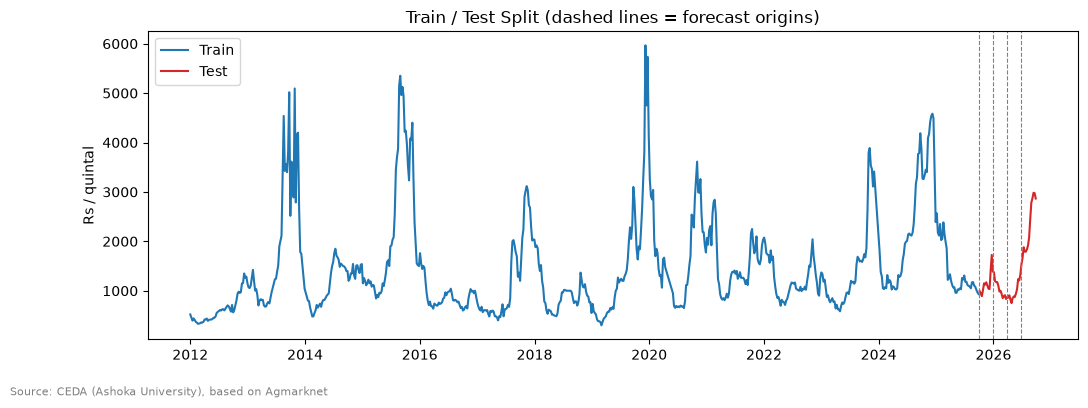

In [21]:
split_date = '2025-09-28'                    # last Sunday of Sep 2025
train = weekly[weekly.index <= split_date]
test = weekly[weekly.index > split_date]
print('Train:', train.index.min().date(), 'to', train.index.max().date(), '|', len(train), 'weeks')
print('Test :', test.index.min().date(), 'to', test.index.max().date(), '|', len(test), 'weeks')

H = 13                                       # forecast horizon = 13 weeks (one quarter)
origins = [test.index[i] - pd.Timedelta(weeks=1) for i in range(0, len(test), H)]
print('\nForecast origins (we pretend "today" is):', [o.date() for o in origins])

plt.plot(train.index, train['price'], label='Train')
plt.plot(test.index, test['price'], label='Test', color='tab:red')
for o in origins:
    plt.axvline(o, color='gray', linestyle='--', linewidth=0.8)
plt.title('Train / Test Split (dashed lines = forecast origins)')
plt.ylabel('Rs / quintal')
plt.legend()
add_source()
plt.show()

# Table that will hold every model's forecasts for the test weeks
predictions = pd.DataFrame({'Actual': test['price']})

### Step 6: Build the models (simplest first)

#### 6(a) Baselines: Naive and Seasonal Naive
**Why:** A baseline is the "no-skill" forecast. If a complex model cannot beat it, the complex model is useless.
* **Naive:** every future week = the last known price.
* **Seasonal naive:** every future week = the price in the same week one year (52 weeks) earlier.

In [22]:
naive_pred, snaive_pred = [], []

for origin in origins:
    history = weekly.loc[:origin, 'price']                 # only data up to 'today'
    future_weeks = test.index[(test.index > origin)][:H]

    last_value = history.iloc[-1]
    naive_pred += [last_value] * len(future_weeks)

    for week in future_weeks:
        snaive_pred.append(history[week - pd.Timedelta(weeks=52)])

predictions['Naive'] = naive_pred
predictions['Seasonal Naive'] = snaive_pred
predictions.head()

,Actual,Naive,Seasonal Naive
date,,,
2025-10-05,991.666667,933.333333,3270.000000
2025-10-12,950.000000,933.333333,3260.000000
2025-10-19,890.000000,933.333333,3341.666667
2025-10-26,1010.000000,933.333333,3450.000000
2025-11-02,1150.000000,933.333333,3400.000000


#### 6(b) SARIMA and SARIMAX

**Why:** SARIMA learns how the price depends on its recent past (AR), past errors (MA) and the same week last year (seasonal AR).

**Choosing the orders, from the EDA:**
* We model the **log of the price**, because prices spike multiplicatively (a 50% jump), and log makes the spikes smaller and the variance more stable.
* The ADF test says the (log) price is already **stationary**, so **d = 0** (no differencing), with a constant (`trend='c'`) for the average level.
* The PACF has a strong spike at lag 1 and the ACF decays slowly → **p = 1**; we add **q = 1** to absorb the short-term noise.
* Seasonality is yearly → seasonal period **s = 52**, with one seasonal AR term **(P = 1)**.

So the model is **SARIMA(1,0,1)(1,0,0,52)** on log price.

**SARIMAX** adds **log(arrivals)** as an external variable. Problem: when we forecast, we don't yet know future arrivals!
To stay honest (no leakage), we use the arrivals of the **same week last year** as the guess for future arrivals.

⏳ *This cell fits 8 models with a 52-week season, so it takes about 3–5 minutes.*

In [23]:
sarima_pred, sarimax_pred = [], []

for origin in origins:
    history = weekly.loc[:origin]
    future_weeks = test.index[(test.index > origin)][:H]

    # ---- SARIMA (price only) ----
    sarima = SARIMAX(np.log(history['price']), order=(1, 0, 1),
                     seasonal_order=(1, 0, 0, 52), trend='c').fit(disp=False)
    sarima_pred += list(np.exp(sarima.forecast(len(future_weeks))))

    # ---- SARIMAX (price + arrivals) ----
    x_train = np.log(history[['arrivals']])
    # future arrivals are unknown -> use same week last year
    x_future = np.log([[history.loc[w - pd.Timedelta(weeks=52), 'arrivals']] for w in future_weeks])
    sarimax = SARIMAX(np.log(history['price']), exog=x_train, order=(1, 0, 1),
                      seasonal_order=(1, 0, 0, 52), trend='c').fit(disp=False)
    sarimax_pred += list(np.exp(sarimax.forecast(len(future_weeks), exog=x_future)))
    print('Done origin', origin.date())

predictions['SARIMA'] = sarima_pred
predictions['SARIMAX'] = sarimax_pred

Done origin 2025-09-28


Done origin 2025-12-28


Done origin 2026-03-29


Done origin 2026-06-28


In [24]:
# Summary of the last SARIMAX model
print(sarimax.summary())

                                      SARIMAX Results                                      
Dep. Variable:                               price   No. Observations:                  757
Model:             SARIMAX(1, 0, 1)x(1, 0, [], 52)   Log Likelihood                 442.753
Date:                             Sat, 14 Nov 2026   AIC                           -873.507
Time:                                     01:16:52   BIC                           -845.731
Sample:                                 01-01-2012   HQIC                          -862.809
                                      - 06-28-2026                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.2194      0.056      3.922      0.000       0.110       0.329
arrivals      -0.0100      

**Observation:** AR(1) = 0.967 is very close to 1: next week's (log) price is almost this week's price, which is why the naive forecast is so strong. The **seasonal AR (0.06, p = 0.11)** is weak and not significant: the same week last year says little about this year. The **arrivals coefficient is −0.010 with p = 0.36**, so it has the correct (negative) sign but is **not statistically significant**. Arrivals add very little once we know recent prices. The Ljung-Box p = 0.80 means no autocorrelation is left in the residuals.

#### 6(c) Lag-feature Random Forest

**Why:** A Random Forest does not understand time by itself. We turn the series into a normal table where each row is one
week and the columns are **features built only from the past**:

| Feature | Meaning |
|---|---|
| lag_1, lag_2, lag_3, lag_4 | price 1, 2, 3, 4 weeks ago |
| lag_52 | price same week last year |
| roll_mean_4, roll_mean_12 | average price of the previous 4 / 12 weeks |
| month | calendar month (captures seasonality) |

`shift(1)` moves the series down by one row, so the rolling means use **only past weeks** — never the current week. This prevents leakage.

**Recursive forecasting:** to forecast 13 weeks ahead we predict week 1, put that prediction back into the series as if it
were real, build the features for week 2, predict, and so on.

In [25]:
def make_features(price):
    # Build lag features from a price series. Only past values are used.
    X = pd.DataFrame(index=price.index)
    for lag in [1, 2, 3, 4, 52]:
        X[f'lag_{lag}'] = price.shift(lag)
    X['roll_mean_4'] = price.shift(1).rolling(4).mean()
    X['roll_mean_12'] = price.shift(1).rolling(12).mean()
    X['month'] = price.index.month
    return X

# Example of the feature table
make_features(weekly['price']).dropna().head()

,lag_1,lag_2,lag_3,lag_4,lag_52,roll_mean_4,roll_mean_12,month
date,,,,,,,,
2012-12-30,1286.0,1265.0,1350.0,1156.0,520.000000,1264.25,1013.805556,12
2013-01-06,1150.0,1286.0,1265.0,1350.0,456.000000,1262.75,1058.972222,1
2013-01-13,1070.0,1150.0,1286.0,1265.0,395.833333,1192.75,1089.138889,1
2013-01-20,1054.0,1070.0,1150.0,1286.0,440.000000,1140.00,1110.305556,1
2013-01-27,1106.0,1054.0,1070.0,1150.0,410.000000,1095.00,1124.138889,1


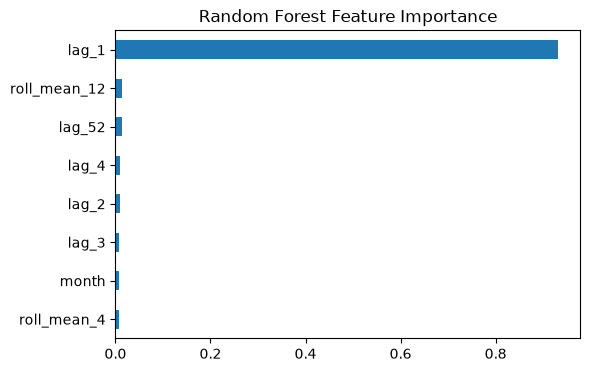

In [26]:
rf_pred = []

for origin in origins:
    history = weekly.loc[:origin, 'price'].copy()
    future_weeks = test.index[(test.index > origin)][:H]

    # train on the past only
    X = make_features(history).dropna()
    y = history.loc[X.index]
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)
    rf.fit(X, y)

    # recursive forecast: predict one week, append it, predict the next
    for week in future_weeks:
        history.loc[week] = np.nan
        x_next = make_features(history).loc[[week]]
        y_next = rf.predict(x_next)[0]
        history.loc[week] = y_next
        rf_pred.append(y_next)

predictions['Random Forest'] = rf_pred

# Which features did the forest use most? (from the last fitted model)
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind='barh', figsize=(6, 4), title='Random Forest Feature Importance')
plt.show()

**Observation:** The forest relies almost entirely on **lag_1** (last week's price, about 93% of the importance). Every other feature, including lag_52 and month, has only about 1% each. This agrees with the SARIMAX result: last week's price carries almost all the information, and the forest has learned little more than a smarter version of the naive forecast.

### Step 7: Evaluate and compare the models

**Why:** We compute MAE, RMSE and MAPE for every model on the same 52 test weeks, and check whether each model beats the
**Naive** baseline (lower MAE).

In [27]:
def evaluate(actual, forecast):
    mae = mean_absolute_error(actual, forecast)
    rmse = np.sqrt(mean_squared_error(actual, forecast))
    mape = np.mean(np.abs((actual - forecast) / actual)) * 100
    return mae, rmse, mape

rows = []
for model in predictions.columns.drop('Actual'):
    mae, rmse, mape = evaluate(predictions['Actual'], predictions[model])
    rows.append([model, mae, rmse, mape])

results = pd.DataFrame(rows, columns=['Model', 'MAE', 'RMSE', 'MAPE (%)']).set_index('Model')
naive_mae = results.loc['Naive', 'MAE']
results['Beats Naive?'] = np.where(results['MAE'] < naive_mae, 'Yes', 'No')
results.loc['Naive', 'Beats Naive?'] = '-'
results['Improvement vs Naive (%)'] = ((naive_mae - results['MAE']) / naive_mae * 100).round(1)
results = results.sort_values('MAE').round(1)
results

,MAE,RMSE,MAPE (%),Beats Naive?,Improvement vs Naive (%)
Model,,,,,
SARIMAX,365.6,555.4,22.5,Yes,4.9
SARIMA,368.3,557.0,22.7,Yes,4.2
Random Forest,371.7,531.6,26.9,Yes,3.3
Naive,384.3,541.7,25.2,-,0.0
Seasonal Naive,1229.0,1587.0,98.9,No,-219.8


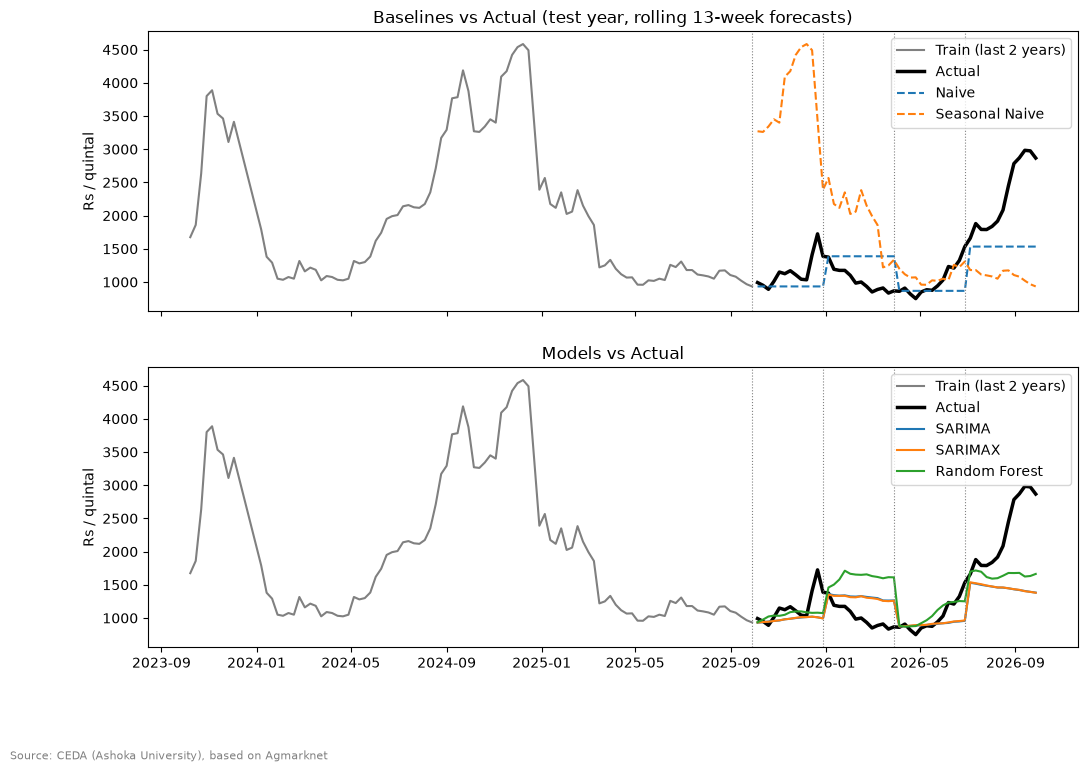

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(train.index[-104:], train['price'][-104:], color='gray', label='Train (last 2 years)')
axes[0].plot(predictions.index, predictions['Actual'], color='black', linewidth=2.5, label='Actual')
axes[0].plot(predictions.index, predictions['Naive'], linestyle='--', label='Naive')
axes[0].plot(predictions.index, predictions['Seasonal Naive'], linestyle='--', label='Seasonal Naive')
axes[0].set_title('Baselines vs Actual (test year, rolling 13-week forecasts)')
axes[0].set_ylabel('Rs / quintal')
axes[0].legend()

axes[1].plot(train.index[-104:], train['price'][-104:], color='gray', label='Train (last 2 years)')
axes[1].plot(predictions.index, predictions['Actual'], color='black', linewidth=2.5, label='Actual')
for model in ['SARIMA', 'SARIMAX', 'Random Forest']:
    axes[1].plot(predictions.index, predictions[model], label=model)
axes[1].set_title('Models vs Actual')
axes[1].set_ylabel('Rs / quintal')
axes[1].legend()

for ax in axes:
    for o in origins:
        ax.axvline(o, color='gray', linestyle=':', linewidth=0.8)
add_source()
plt.savefig('figures/07_forecast_vs_actual.png', bbox_inches='tight')
plt.show()

**Observation:** **SARIMAX has the lowest MAE (Rs 366/quintal, MAPE 22.5%)**, then SARIMA and Random Forest. All three beat the naive baseline on MAE, but **only by 3–5%**. Random Forest is worse than naive on MAPE (26.9% vs 25.2%), so it does not clearly beat naive. **Seasonal naive is by far the worst** (MAPE 99%): Oct–Dec 2024 was a crisis year (Rs 3,000–4,500) and 2025 was not, so copying last year was badly wrong. The plot shows the main weakness of all the models. In Jul–Sep 2026 prices rose from Rs 1,500 to Rs 3,000, and every model missed the size of the rise: they predicted a slow return towards the average level. **Honest verdict:** SARIMAX is the best model, but its advantage over the naive 'last price' forecast is small.

### Step 8: Retrain the best model on all data and forecast Oct–Dec 2026

**Why:** For the final forecast we use **all** the data up to Sep-2026 (the test year is now also history), so the model
knows the most recent prices. We forecast 13 weeks (Oct–Dec 2026) and show **prediction intervals**:
* **80% interval** – the price should fall inside this band in about 8 out of 10 weeks.
* **95% interval** – wider; the price should fall inside in about 19 out of 20 weeks.

The intervals come from the model on the log scale and are converted back with `exp()`.

In [29]:
best_model = results.drop(['Naive', 'Seasonal Naive']).index[0]   # best of the real models (lowest MAE)
print('Best model on the test set:', best_model)

future_weeks = pd.date_range(weekly.index[-1] + pd.Timedelta(weeks=1), periods=13, freq='W')
print('Forecasting weeks:', future_weeks[0].date(), 'to', future_weeks[-1].date())

if best_model == 'SARIMAX':
    x_all = np.log(weekly[['arrivals']])
    x_future = np.log([[weekly.loc[w - pd.Timedelta(weeks=52), 'arrivals']] for w in future_weeks])
    final_model = SARIMAX(np.log(weekly['price']), exog=x_all, order=(1, 0, 1),
                          seasonal_order=(1, 0, 0, 52), trend='c').fit(disp=False)
    fc = final_model.get_forecast(13, exog=x_future)
else:
    # SARIMA (also used for intervals if Random Forest wins, because a forest gives no interval)
    final_model = SARIMAX(np.log(weekly['price']), order=(1, 0, 1),
                          seasonal_order=(1, 0, 0, 52), trend='c').fit(disp=False)
    fc = final_model.get_forecast(13)

ci80 = np.exp(fc.conf_int(alpha=0.20))
ci95 = np.exp(fc.conf_int(alpha=0.05))
forecast = pd.DataFrame({
    'Forecast': np.exp(fc.predicted_mean).values,
    'Lower 80%': ci80.iloc[:, 0].values, 'Upper 80%': ci80.iloc[:, 1].values,
    'Lower 95%': ci95.iloc[:, 0].values, 'Upper 95%': ci95.iloc[:, 1].values,
}, index=future_weeks).round(0)
forecast.index.name = 'week_ending'
forecast

Best model on the test set: SARIMAX
Forecasting weeks: 2026-10-04 to 2026-12-27


,Forecast,Lower 80%,Upper 80%,Lower 95%,Upper 95%
week_ending,,,,,
2026-10-04,2778.0,2341.0,3298.0,2137.0,3612.0
2026-10-11,2691.0,2095.0,3456.0,1835.0,3946.0
2026-10-18,2617.0,1926.0,3556.0,1638.0,4182.0
2026-10-25,2587.0,1821.0,3675.0,1512.0,4425.0
2026-11-01,2531.0,1716.0,3731.0,1397.0,4583.0
2026-11-08,2486.0,1633.0,3785.0,1307.0,4728.0
2026-11-15,2420.0,1546.0,3789.0,1219.0,4803.0
2026-11-22,2355.0,1467.0,3779.0,1142.0,4854.0
2026-11-29,2300.0,1402.0,3773.0,1079.0,4903.0


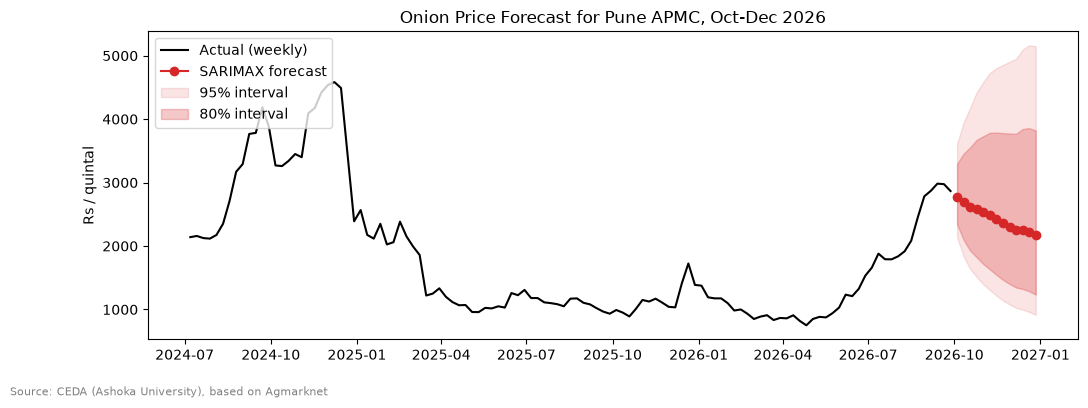

In [30]:
recent = weekly.loc['2024-07-01':, 'price']
plt.plot(recent.index, recent, color='black', label='Actual (weekly)')
plt.plot(forecast.index, forecast['Forecast'], color='tab:red', marker='o', label=f'{best_model} forecast')
plt.fill_between(forecast.index, forecast['Lower 95%'], forecast['Upper 95%'], color='tab:red', alpha=0.12, label='95% interval')
plt.fill_between(forecast.index, forecast['Lower 80%'], forecast['Upper 80%'], color='tab:red', alpha=0.25, label='80% interval')
plt.title('Onion Price Forecast for Pune APMC, Oct-Dec 2026')
plt.ylabel('Rs / quintal')
plt.legend(loc='upper left')
add_source()
plt.savefig('figures/08_forecast_oct_dec_2026.png', bbox_inches='tight')
plt.show()

In [31]:
# Monthly summary of the forecast
monthly_fc = forecast.groupby(forecast.index.month)[['Forecast', 'Lower 80%', 'Upper 80%']].mean().round(0)
monthly_fc.index = ['Oct 2026', 'Nov 2026', 'Dec 2026']
print(monthly_fc)

# Save the forecast; the empty 'Actual' column is to be filled in as real prices come out
forecast_out = forecast.copy()
forecast_out['Actual'] = np.nan
forecast_out.to_csv('forecast_oct_dec_2026.csv')
print('\nSaved forecast_oct_dec_2026.csv')

          Forecast  Lower 80%  Upper 80%
Oct 2026    2668.0     2046.0     3496.0
Nov 2026    2418.0     1553.0     3771.0
Dec 2026    2227.0     1298.0     3823.0

Saved forecast_oct_dec_2026.csv


**Observation:** The final SARIMAX forecast starts at about Rs 2,780 in early October and slowly declines to about Rs 2,170 by the end of December (monthly averages: Oct ≈ Rs 2,670, Nov ≈ Rs 2,420, Dec ≈ Rs 2,230). The intervals are wide and widen every week: by December the 80% interval is about Rs 1,300–3,800. **Be careful when reading this:** the downward slope comes from the model's mean-reversion (prices usually come back to normal after a rise). It does *not* come from the usual Oct–Nov seasonal peak, which the model barely captures. If 2026 follows the typical seasonal pattern, actual prices could stay at or above the upper half of the interval in Oct–Nov.

#### 8.1 Checking the forecast later
When real prices for Oct–Dec 2026 are published on Agmarknet / CEDA, fill the `Actual` column in
`forecast_oct_dec_2026.csv` (weekly average of Pune modal price) and run the cell below.

In [32]:
check = pd.read_csv('forecast_oct_dec_2026.csv', parse_dates=['week_ending']).dropna(subset=['Actual'])
if len(check) == 0:
    print('No actual prices filled in yet.')
else:
    mae, rmse, mape = evaluate(check['Actual'], check['Forecast'])
    inside = ((check['Actual'] >= check['Lower 80%']) & (check['Actual'] <= check['Upper 80%'])).mean() * 100
    print(f'Weeks checked: {len(check)}  MAE: {mae:.0f}  RMSE: {rmse:.0f}  MAPE: {mape:.1f}%')
    print(f'Actual price inside the 80% interval in {inside:.0f}% of weeks')

No actual prices filled in yet.


## 7. Interpretation
The raw Pune APMC data had dates stored as text, 58 days without a price (mostly December 2023 and Aug–Sep 2014), 55 days without arrivals, and many extreme prices. The extreme prices were checked and found to be real crisis events (December 2019, COVID-2020, 2023–24), so they were kept. The daily data was converted into a regular weekly series of 770 weeks, and 18 empty weeks were filled by interpolation.

EDA showed that onion prices have (i) a **strong yearly seasonality**: cheapest in April (median Rs 729) and dearest in November (median Rs 2,071); (ii) **no steady trend** but repeated boom–bust cycles; (iii) a **weak negative relation with arrivals** (r ≈ −0.22); and (iv) **stationarity** according to the ADF test, with a strong AR(1) structure in the ACF/PACF.

On the test year (Oct-2025 to Sep-2026, rolling 13-week forecasts) the results were:

| Model | MAE (Rs/q) | RMSE (Rs/q) | MAPE (%) | Beats Naive? |
|---|---|---|---|---|
| SARIMAX (1,0,1)(1,0,0,52) + arrivals | **365.6** | 555.4 | **22.5** | Yes (+4.9%) |
| SARIMA (1,0,1)(1,0,0,52) | 368.3 | 557.0 | 22.7 | Yes (+4.2%) |
| Random Forest (lag features) | 371.7 | **531.6** | 26.9 | Yes on MAE (+3.3%), no on MAPE |
| Naive (last value) | 384.3 | 541.7 | 25.2 | – |
| Seasonal Naive (last year) | 1229.0 | 1587.0 | 98.9 | No |

SARIMAX was the best model, but its advantage over the naive forecast is small (about 5%), and the arrivals variable was not statistically significant. The final SARIMAX model forecasts an average Pune modal price of about **Rs 2,670 (Oct), Rs 2,420 (Nov) and Rs 2,230 (Dec 2026)** per quintal, with wide 80% intervals (e.g. Rs 1,300–3,800 in December).

## 8. Required Python Libraries
Install the required libraries using:
```
pip install pandas numpy matplotlib statsmodels scikit-learn
```
(or `pip install -r requirements.txt`)

Import them using:
```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
```

## 9. Precautions
* Never shuffle time series data; always train on the past and test on the future.
* Build lag and rolling features with `shift()` so that only **past** values are used (no data leakage).
* Do not use future values of an external variable (arrivals) that would not be known at forecast time.
* Always compare against a **naive baseline** before trusting a complex model.
* Check outliers before removing them — price spikes in agricultural markets are usually real events (crop failure, export bans), not errors.
* Make the series regular (weekly) and fill gaps before applying ARIMA-type models.
* Model prices on the log scale when they have large multiplicative spikes.
* Prediction intervals matter as much as the forecast itself: onion prices are highly volatile.

## 10. Conclusion
In this mini project, time series analysis was performed on 14 years of daily onion prices from Pune APMC (CEDA / Agmarknet). The data was cleaned, converted to a weekly series, and analysed for trend, seasonality, the effect of arrivals and stationarity. Five forecasting models were compared using a time-based split without leakage. SARIMAX(1,0,1)(1,0,0,52) with arrivals gave the lowest error (MAE ≈ Rs 366/quintal, MAPE ≈ 22.5%), but it beat the simple naive forecast by only about 5%. This shows that **onion prices are mostly driven by sudden supply shocks (rain damage, export policy) that past prices cannot predict.** The model was retrained on all data and used to forecast Oct–Dec 2026 with 80% and 95% prediction intervals. These will be checked against the real prices as they are published.

**Limitations:** (1) arrivals for the future are unknown, so last year's arrivals were used as a guess; (2) weather, rainfall, storage stocks and export/import policy, the real drivers of onion crises, are not in the data; (3) the model reverts to the average level and under-weights the Oct–Nov seasonal peak; (4) the test year contains only one rising period, so the comparison is based on a limited sample; (5) interpolated weeks (COVID-2020, Dec-2023) are estimates, not real prices.

**Future scope:** add rainfall and export-policy variables, try a model with Fourier seasonal terms, or use a rolling (expanding-window) evaluation over several years.